# 02 · Customer Segmentation: SQL RFM vs K-Means Clustering

**Project:** E-Commerce Customer Segmentation & Retention (Python + SQL + ML)

### Goal
Group customers by behaviour so the business can treat different groups differently.
I use **two approaches** and compare them:
1. **Rule-based RFM segments** (built in SQL, `sql/03_rfm_segmentation.sql`) → easy to explain
2. **K-Means clustering** (Python, machine learning) → lets the data decide the groups

### A new concept I learned for this project: K-Means (unsupervised learning)
In my earlier ML study (linear regression, classification) the data had a **target** to predict (supervised learning). Segmentation has **no target** — nobody tells the model what the "right" groups are. That is *unsupervised learning*.
K-Means in plain words:
1. Choose **k** (number of groups).
2. Drop k random "centres" among the customers.
3. Assign every customer to the nearest centre.
4. Move each centre to the average of its customers. Repeat 3-4 until nothing changes.

Because "nearest" uses **distance**, two things matter: features must be on a **similar scale**, and extreme outliers must be tamed. I test both below instead of assuming.

## Step 0 · Setup

In [1]:
import sys                                   # lets me add the src/ folder so I can import my own helper file
sys.path.append("../src")
import pandas as pd                          # tables
import numpy as np                           # maths (log transform)
import matplotlib.pyplot as plt              # base charts
import seaborn as sns                        # nicer charts
from pathlib import Path                     # file paths

from sklearn.preprocessing import StandardScaler          # puts features on the same scale (mean 0, std 1)
from sklearn.cluster import KMeans                        # the clustering algorithm
from sklearn.metrics import silhouette_score, adjusted_rand_score   # two ways to evaluate clusters
from sklearn.decomposition import PCA                     # squashes 3 features to 2 so I can draw them

from db_utils import read_sql_or_csv                      # my helper: MySQL first, CSV as backup

sns.set_theme(style="whitegrid", palette="deep")          # same look as notebook 01
pd.options.display.float_format = "{:,.2f}".format
RANDOM_STATE = 42                                         # fixed seed -> same results every time I run it
IMAGES = Path("../images")
PROCESSED = Path("../data/processed")

## Step 1 · Load the RFM table from MySQL
**What:** read the `customer_rfm` table that my SQL script created. **Why:** this is the *SQL → Python hand-off* of the project: SQL does the heavy aggregation over 776k rows, Python does the modelling.

In [2]:
# SQL query that returns one row per customer with R, F, M, scores and the rule-based segment
query = "SELECT * FROM customer_rfm"
rfm = read_sql_or_csv(query, csv_fallback=PROCESSED / "customer_rfm.csv")

# MySQL returns the 1-5 scores as decimals; convert them to whole numbers so they display as 1, 2, 3...
rfm[["r_score", "f_score", "m_score"]] = rfm[["r_score", "f_score", "m_score"]].astype(int)

print("Shape:", rfm.shape)
rfm.head()

Loaded from MySQL
Shape: (5832, 16)


,customer_id,recency_days,frequency,monetary,gross_sales,returned_value,first_order_date,last_order_date,is_uk,r_score,f_score,m_score,avg_order_value,tenure_days,rfm_code,segment
0,12346,326,3,169.36,"77,352.96","-77,183.60",2010-03-02,2011-01-18,1,2,3,1,56.45,648,231,At Risk
1,12347,3,8,"4,921.53","4,921.53",0.00,2010-10-31,2011-12-07,0,5,4,5,615.19,405,545,Champions
2,12348,76,5,"1,658.40","1,658.40",0.00,2010-09-27,2011-09-25,0,3,4,4,331.68,439,344,Loyal Customers
3,12349,19,3,"3,654.54","3,678.69",-24.15,2010-04-29,2011-11-21,0,5,3,5,"1,218.18",590,535,Potential Loyalists
4,12350,311,1,294.40,294.40,0.00,2011-02-02,2011-02-02,0,2,1,2,294.40,311,212,Hibernating


In [3]:
# ---- Evaluation: is the table what I expect? ----
assert rfm["customer_id"].is_unique, "a customer appears twice!"          # exactly one row per customer
assert rfm[["recency_days", "frequency", "monetary"]].notna().all().all(), "missing values in R/F/M"
assert (rfm["monetary"] > 0).all(), "net spend should be positive (customers with net <= 0 were removed in SQL)"
print("Checks passed -", f"{len(rfm):,} customers")

rfm[["recency_days", "frequency", "monetary"]].describe()      # min / mean / quartiles / max for R, F and M

Checks passed - 5,832 customers


,recency_days,frequency,monetary
count,"5,832.00","5,832.00","5,832.00"
mean,200.38,6.27,"2,805.48"
std,208.38,12.77,"13,847.92"
min,1.00,1.00,2.90
25%,26.00,1.00,333.79
50%,96.00,3.00,843.74
75%,379.00,7.00,"2,179.89"
max,739.00,373.00,"578,408.64"


**Evaluation:** one row per customer, no missing values. The `describe()` output already hints at a problem: the **mean of `monetary` is far above its median** (50% value) and the max is huge → very right-skewed. I check this properly in Step 3.

## Step 2 · The SQL rule-based segments: how much money sits in each group?
**What:** chart each segment's share of customers vs share of revenue. **Why:** a segment is only useful if it tells me where the money is.

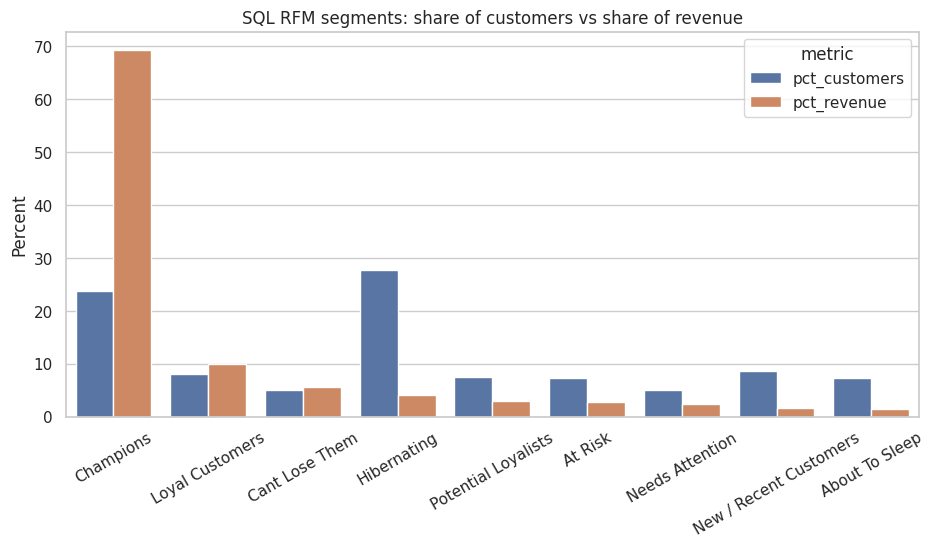

,customers,revenue,pct_customers,pct_revenue
segment,,,,
Champions,1380,"11,342,766.90",23.70,69.30
Loyal Customers,472,"1,619,830.10",8.10,9.90
Cant Lose Them,289,"917,071.40",5.00,5.60
Hibernating,1620,"674,956.00",27.80,4.10
Potential Loyalists,437,"485,619.50",7.50,3.00
At Risk,424,"455,390.10",7.30,2.80
Needs Attention,287,"371,963.80",4.90,2.30
New / Recent Customers,503,"269,126.70",8.60,1.60
About To Sleep,420,"224,860.40",7.20,1.40


In [4]:
# for each SQL segment: % of customers and % of revenue
seg = (rfm.groupby("segment")
          .agg(customers=("customer_id", "size"), revenue=("monetary", "sum")))   # count and total money
seg["pct_customers"] = seg["customers"] / seg["customers"].sum() * 100              # share of customers
seg["pct_revenue"] = seg["revenue"] / seg["revenue"].sum() * 100                    # share of revenue
seg = seg.sort_values("pct_revenue", ascending=False)                               # biggest revenue first

# reshape from wide to long so seaborn can draw two bars per segment
plot_df = seg[["pct_customers", "pct_revenue"]].reset_index().melt(id_vars="segment", var_name="metric", value_name="percent")

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=plot_df, x="segment", y="percent", hue="metric", ax=ax)
ax.set_title("SQL RFM segments: share of customers vs share of revenue")
ax.set_xlabel("")
ax.set_ylabel("Percent")
ax.tick_params(axis="x", rotation=30)
plt.savefig(IMAGES / "08_rfm_segments_customers_vs_revenue.png", dpi=150, bbox_inches="tight")
plt.show()
seg.round(1)

**Insight:** *Champions* are ~24% of customers but ~69% of revenue; *Hibernating* is the biggest group by headcount (~28%) yet only ~4% of revenue. The rules work, but the **boundaries between segments are fixed by me** (e.g. "score >= 4"). Is there a more natural grouping in the data? That is what K-Means will tell me.

## Step 3 · Prepare features for K-Means
K-Means uses distance, so I check **skewness** (0 = symmetric; above ~1 = strongly skewed) before anything else.

In [5]:
# the three behaviour features (these are the same R, F, M as in SQL)
features = ["recency_days", "frequency", "monetary"]
X = rfm[features].copy()

# skewness before any transformation
print("Skewness BEFORE log transform")
print(X.skew().round(2))

# log1p = log(1 + x). I use 1+x because log(0) is undefined (it is safe even if a value were 0).
X_log = np.log1p(X)
print("\nSkewness AFTER log transform")
print(X_log.skew().round(2))

Skewness BEFORE log transform
recency_days    0.90
frequency      12.03
monetary       26.78
dtype: float64

Skewness AFTER log transform
recency_days   -0.44
frequency       1.00
monetary        0.25
dtype: float64


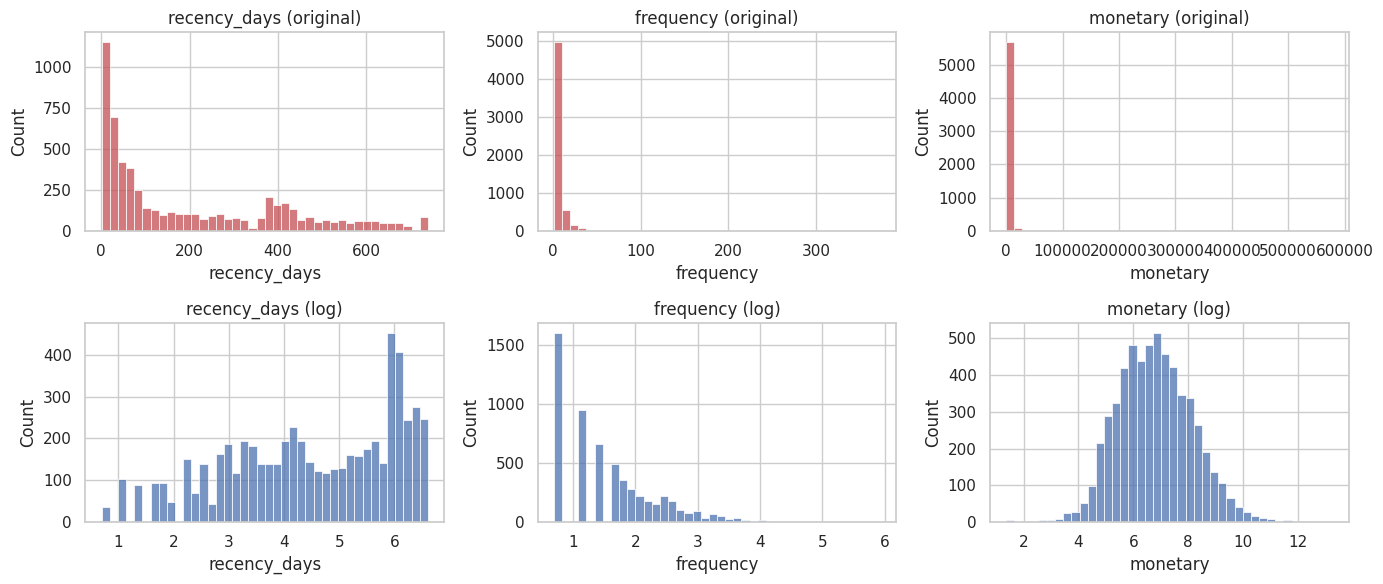

In [6]:
# draw before/after histograms to SEE the effect (2 rows x 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for i, col in enumerate(features):
    sns.histplot(X[col], bins=40, ax=axes[0, i], color="#C44E52")        # before
    axes[0, i].set_title(f"{col} (original)")
    sns.histplot(X_log[col], bins=40, ax=axes[1, i], color="#4C72B0")    # after
    axes[1, i].set_title(f"{col} (log)")
plt.tight_layout()
plt.savefig(IMAGES / "09_rfm_log_transform.png", dpi=150, bbox_inches="tight")
plt.show()

**Evaluation:** frequency (skew ≈ 12) and monetary (skew ≈ 27) are *extremely* skewed; after the log transform they are much closer to symmetric (skew of about 1 or less). Recency was already fairly balanced.

### My first attempt (without log transform) — and why I rejected it
Before trusting the transform I tested what K-Means does on **only-scaled raw data**. If the log step is really needed, this should go wrong.

In [7]:
# Attempt 1: standardise the RAW values (no log) and run K-Means with k=4
raw_scaled = StandardScaler().fit_transform(X)                       # mean 0, std 1 per column
km_raw = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(raw_scaled)

print("Cluster sizes (raw, no log):", np.bincount(km_raw.labels_))   # how many customers in each cluster
print("Silhouette score (raw, no log):", round(silhouette_score(raw_scaled, km_raw.labels_), 3))

Cluster sizes (raw, no log): [  37 3819 1972    4]


Silhouette score (raw, no log): 0.59


**Evaluation (important lesson):** without the log transform, K-Means creates **two tiny clusters (4 and 37 customers)** — it just isolates the extreme spenders — and splits the other ~5,800 customers into two big blobs. That is useless for marketing.
Also notice the **silhouette score looks high (~0.59)**. If I had only looked at that number I might have thought this was a great result! A high score does not mean the clusters are *useful*. Lesson: **never trust one metric — look at cluster sizes and business meaning too.**

In [8]:
# Attempt 2 (final approach): log transform FIRST, then standardise
scaler = StandardScaler()                                # remembers mean/std of each column
Z = scaler.fit_transform(X_log)                          # Z = the final feature matrix (mean 0, std 1 per column)

print("Mean of each column (should be ~0):", Z.mean(axis=0).round(3))
print("Std  of each column (should be ~1):", Z.std(axis=0).round(3))

Mean of each column (should be ~0): [-0.  0. -0.]
Std  of each column (should be ~1): [1. 1. 1.]


## Step 4 · How many clusters? (choosing k)
**What:** try k = 2 … 8 and compare two measures.
- **Inertia (elbow method):** total squared distance of customers to their own centre. Always falls as k grows; I look for where the improvement slows down.
- **Silhouette score:** how well each customer fits its own cluster compared with the nearest other cluster (-1 to 1; higher is better).

In [9]:
results = []                                             # will hold one dictionary per k
for k in range(2, 9):                                    # k = 2, 3, ... 8
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)    # n_init=10 -> try 10 starting positions, keep the best
    results.append({
        "k": k,
        "inertia": km.inertia_,                          # the 'elbow' measure
        "silhouette": silhouette_score(Z, km.labels_),   # cluster quality
        "smallest_cluster": np.bincount(km.labels_).min()  # a quick check that no cluster is tiny
    })
k_results = pd.DataFrame(results)
k_results

,k,inertia,silhouette,smallest_cluster
0,2,"8,520.84",0.44,2320
1,3,"6,293.96",0.35,1238
2,4,"4,861.86",0.37,1189
3,5,"4,041.46",0.35,449
4,6,"3,516.23",0.33,459
5,7,"3,153.48",0.31,269
6,8,"2,871.43",0.29,388


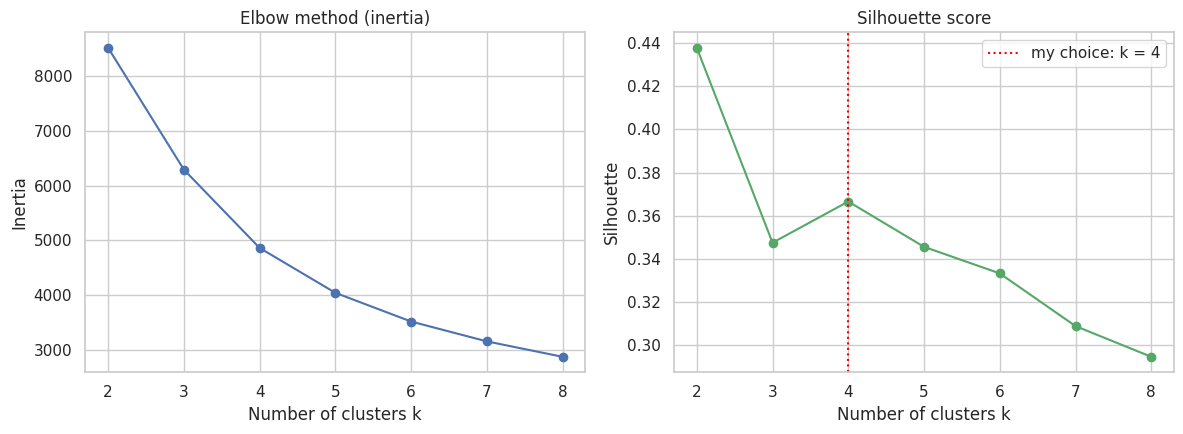

In [10]:
# two charts side by side: elbow and silhouette
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(k_results["k"], k_results["inertia"], marker="o")
axes[0].set_title("Elbow method (inertia)")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_results["k"], k_results["silhouette"], marker="o", color="#55A868")
axes[1].axvline(4, color="red", linestyle=":", label="my choice: k = 4")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette")
axes[1].legend()
plt.tight_layout()
plt.savefig(IMAGES / "10_kmeans_choose_k.png", dpi=150, bbox_inches="tight")
plt.show()

**Decision: k = 4.** My reasoning (including what does *not* support it):
- The elbow is **not sharp** — inertia falls smoothly, and the improvement flattens gradually after k = 4.
- Silhouette is highest at **k = 2 (0.44)**, but two groups ("good" and "bad" customers) are too coarse to plan different campaigns.
- Between k = 3 (0.35) and k = 4 (0.37) the silhouette actually **goes up**, and k = 4 is the last value before it keeps declining. 
- k = 4 gives groups that are big enough to act on (smallest ≈ 1,200 customers) and easy to explain.
- A silhouette of ~0.37 means **moderate** structure: customer behaviour is more of a continuum than separate islands. That is normal for RFM data and I should not oversell the clusters as "natural" groups.

## Step 5 · Are the clusters stable?
**What:** run K-Means with different random seeds and measure how similar the results are using the **Adjusted Rand Index (ARI)** (1.0 = identical groupings). **Why:** if the result changes every time I run it, I cannot trust it.

In [11]:
labels_by_seed = []
for seed in [1, 2, 3, 4, 5]:                                            # five different random starts
    km = KMeans(n_clusters=4, n_init=10, random_state=seed).fit(Z)
    labels_by_seed.append(km.labels_)

# compare every run against the first one
for i in range(1, 5):
    ari = adjusted_rand_score(labels_by_seed[0], labels_by_seed[i])     # similarity of the two groupings
    print(f"Seed 1 vs seed {i+1}: ARI = {ari:.4f}")

Seed 1 vs seed 2: ARI = 0.9995
Seed 1 vs seed 3: ARI = 0.9990
Seed 1 vs seed 4: ARI = 1.0000
Seed 1 vs seed 5: ARI = 0.9962


**Evaluation:** ARI is ~0.99+ in every comparison → the 4 clusters are **very stable**; a different random start gives (almost) the same groups.

## Step 6 · Final model and cluster profiles
**What:** fit the final K-Means (k = 4), attach the cluster to every customer, and describe each cluster in business terms using the **original** (not log) numbers.

In [12]:
# final model
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(Z)
rfm["cluster_id"] = kmeans.labels_                                      # add the cluster number to each customer

# profile: average R/F/M (original units), size, and money share per cluster
profile = (rfm.groupby("cluster_id")
              .agg(customers=("customer_id", "size"),
                   avg_recency_days=("recency_days", "mean"),
                   avg_orders=("frequency", "mean"),
                   avg_net_spend=("monetary", "mean"),
                   total_net_revenue=("monetary", "sum")))
profile["pct_customers"] = profile["customers"] / profile["customers"].sum() * 100
profile["pct_revenue"] = profile["total_net_revenue"] / profile["total_net_revenue"].sum() * 100
profile.round(1)

,customers,avg_recency_days,avg_orders,avg_net_spend,total_net_revenue,pct_customers,pct_revenue
cluster_id,,,,,,,
0,1440,227.20,5.10,"1,859.90","2,678,188.60",24.70,16.40
1,1189,28.20,19.10,"10,133.80","12,049,086.40",20.40,73.60
2,1253,29.10,3.00,818.30,"1,025,356.20",21.50,6.30
3,1950,395.60,1.40,312.30,"608,953.60",33.40,3.70


In [13]:
# Give each cluster a business name using RULES on its profile (so the names stay correct even if cluster numbers change).
# Rule 1: highest average spend            -> 'VIP Loyalists'
# Rule 2: of the rest, most recent buyers   -> 'Active Newcomers'
# Rule 3: of the remaining two, higher spend -> 'Slipping Regulars', the other -> 'Lost One-Timers'
names = {}
vip = profile["avg_net_spend"].idxmax()                                           # cluster with the biggest spenders
names[vip] = "VIP Loyalists"
rest = profile.drop(index=vip)                                                    # remove VIP from the list
active = rest["avg_recency_days"].idxmin()                                        # most recently active among the rest
names[active] = "Active Newcomers"
rest = rest.drop(index=active)
names[rest["avg_net_spend"].idxmax()] = "Slipping Regulars"                       # quiet but still decent spenders
names[rest["avg_net_spend"].idxmin()] = "Lost One-Timers"                         # quiet and low spenders

rfm["cluster_name"] = rfm["cluster_id"].map(names)                                # add readable names
profile["cluster_name"] = profile.index.map(names)
profile = profile.set_index("cluster_name").sort_values("avg_net_spend", ascending=False)
profile.round(1)

,customers,avg_recency_days,avg_orders,avg_net_spend,total_net_revenue,pct_customers,pct_revenue
cluster_name,,,,,,,
VIP Loyalists,1189,28.20,19.10,"10,133.80","12,049,086.40",20.40,73.60
Slipping Regulars,1440,227.20,5.10,"1,859.90","2,678,188.60",24.70,16.40
Active Newcomers,1253,29.10,3.00,818.30,"1,025,356.20",21.50,6.30
Lost One-Timers,1950,395.60,1.40,312.30,"608,953.60",33.40,3.70


**What the four groups mean** (numbers from the table above):
| Cluster | Behaviour | Business meaning |
|---|---|---|
| **VIP Loyalists** | ordered recently (~4 weeks ago), ~19 orders, ~£10k net spend each | ~20% of customers but ~74% of revenue → protect at all costs |
| **Active Newcomers** | ordered recently, only ~3 orders, ~£800 | recent buyers with growth potential → nurture into loyal customers |
| **Slipping Regulars** | ~7 months since last order, ~5 orders, ~£1.9k | used to buy regularly, now quiet → win-back target |
| **Lost One-Timers** | >1 year silent, ~1 order, ~£300 | lowest value, probably gone → low-cost automated outreach only |

### Visual check 1: customer map (PCA)
I cannot draw 3 dimensions easily, so **PCA** compresses R/F/M into 2 axes that keep as much information as possible.

Variance explained by the 2 axes: [0.763 0.188] -> total 0.951


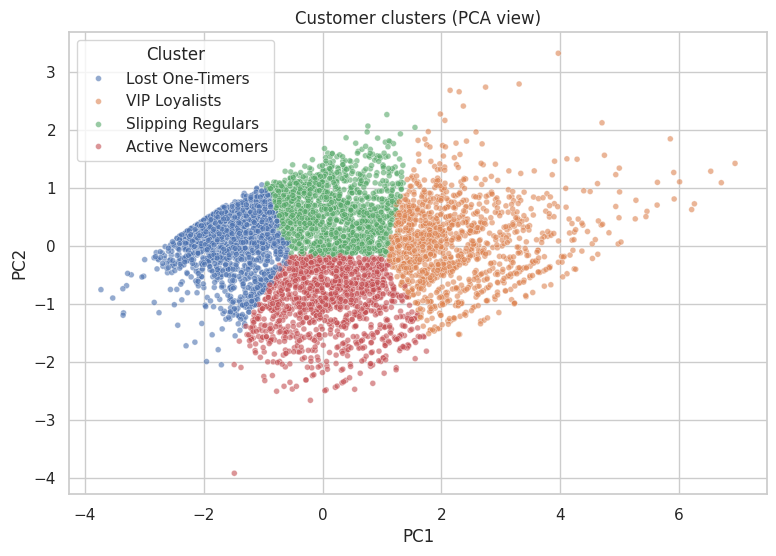

In [14]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)             # keep 2 components
pcs = pca.fit_transform(Z)                                       # coordinates of each customer on the 2 new axes
print("Variance explained by the 2 axes:", pca.explained_variance_ratio_.round(3), "-> total", pca.explained_variance_ratio_.sum().round(3))

plot_df = pd.DataFrame({"PC1": pcs[:, 0], "PC2": pcs[:, 1], "Cluster": rfm["cluster_name"]})
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Cluster", alpha=0.6, s=18, ax=ax)
ax.set_title("Customer clusters (PCA view)")
plt.savefig(IMAGES / "11_kmeans_clusters_pca.png", dpi=150, bbox_inches="tight")
plt.show()

**Evaluation:** the 2 PCA axes keep ~95% of the information, so this picture is a faithful summary. The groups form a **continuous band** with clear regions rather than isolated blobs — consistent with the moderate silhouette score. So these are *useful buckets*, not *natural species*.

### Visual check 2: what makes each cluster different? (heatmap of standardised averages)

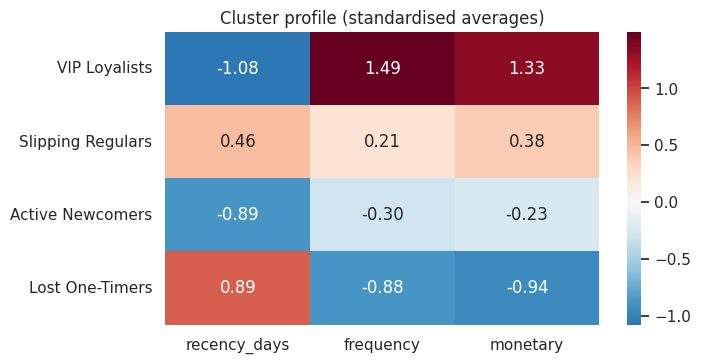

In [15]:
# average of the STANDARDISED features per cluster: positive = above average, negative = below average
z_df = pd.DataFrame(Z, columns=features, index=rfm.index)
z_df["cluster_name"] = rfm["cluster_name"]
z_profile = z_df.groupby("cluster_name")[features].mean().loc[profile.index]   # keep the same order as the profile table

fig, ax = plt.subplots(figsize=(7, 3.8))
sns.heatmap(z_profile, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)   # red = high, blue = low
ax.set_title("Cluster profile (standardised averages)")
ax.set_ylabel("")
plt.savefig(IMAGES / "12_cluster_profile_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

Note for reading: for **recency**, red means *more days since the last order* (= worse). VIP Loyalists are blue on recency (recent) and red on frequency and monetary — exactly what a loyal, high-value group should look like.

## Step 7 · Compare: SQL rule-based segments vs K-Means clusters
**What:** a cross-table showing where each K-Means cluster's customers sit in the SQL segments. **Why:** if both methods agree on the big picture, I can trust the findings more; where they disagree I learn something.

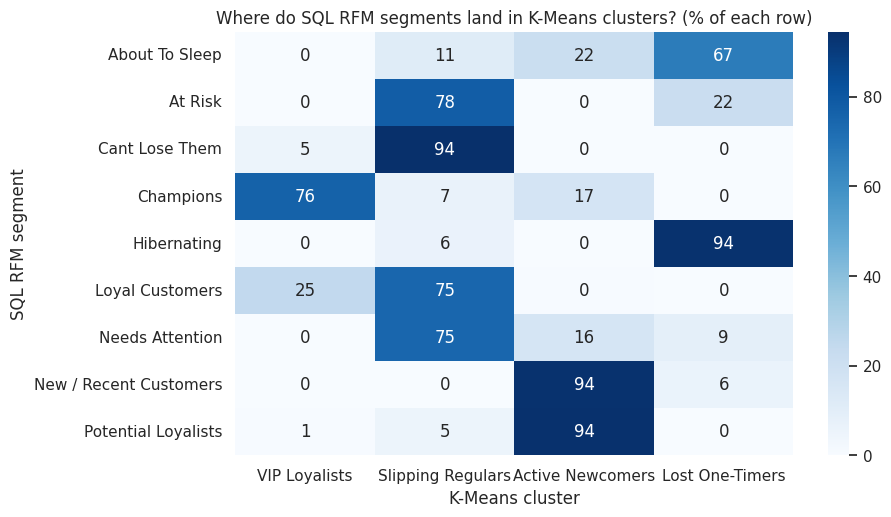

In [16]:
# crosstab: rows = SQL segment, columns = K-Means cluster; normalize='index' -> each row sums to 100%
ct = pd.crosstab(rfm["segment"], rfm["cluster_name"], normalize="index") * 100
ct = ct[profile.index]                                           # order the columns like the profile table

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", ax=ax)       # numbers = % of that SQL segment in each cluster
ax.set_title("Where do SQL RFM segments land in K-Means clusters? (% of each row)")
ax.set_xlabel("K-Means cluster")
ax.set_ylabel("SQL RFM segment")
plt.savefig(IMAGES / "13_sql_segments_vs_kmeans.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight (read each row: where do that SQL segment's customers end up?):**
- **Strong agreement** (≈94%): *Hibernating* → Lost One-Timers, *New / Recent* and *Potential Loyalists* → Active Newcomers, *Can't Lose Them* → Slipping Regulars. 76% of *Champions* → VIP Loyalists.
- **Interesting disagreement:** 75% of SQL's *Loyal Customers* and 75% of *Needs Attention* are placed in **Slipping Regulars** by K-Means. My R-score rule treats ~3-4 months of silence as "still fairly recent"; K-Means draws the line earlier because it compares everyone on the same log-scaled distance. Worth knowing before trusting my hand-made thresholds.
- Also, 17% of SQL *Champions* fall in **Active Newcomers**: they score well on recency/frequency ranks but their spend is modest compared with true VIPs. This is a gap in a rule that ignores monetary value for the label.

**How I would use both:** SQL RFM segments are easy to explain to non-technical stakeholders and to put in a dashboard; K-Means is a useful cross-check and shows where my hand-picked thresholds might be too rigid.

## Step 8 · Recommended actions per cluster
| Cluster | Goal | Action ideas |
|---|---|---|
| VIP Loyalists | Protect | Dedicated account manager, early access to new ranges (before the Sept–Nov peak), loyalty pricing |
| Active Newcomers | Grow | Welcome series, bundle offers, reminder email ~30 days after the order |
| Slipping Regulars | Win back | Personal "we miss you" outreach, re-order reminders for their usual products, limited-time incentive |
| Lost One-Timers | Low-cost reactivation | One automated seasonal email; stop spending on heavy discounts |

These are hypotheses to **test with A/B experiments** — I have no data on campaign response, so I cannot claim they will work.

In [17]:
# ---- Save results for the next notebooks ----
out_cols = ["customer_id", "recency_days", "frequency", "monetary", "segment", "cluster_id", "cluster_name"]
rfm[out_cols].to_csv(PROCESSED / "customer_segments.csv", index=False)                 # used by notebook 04

profile.round(2).to_csv(Path("../outputs") / "kmeans_cluster_profile.csv")             # summary table for the README
seg.round(2).to_csv(Path("../outputs") / "sql_rfm_segment_summary.csv")
print("Saved customer_segments.csv with", len(rfm), "rows")

Saved customer_segments.csv with 5832 rows


## Summary & what I learned
- ✅ Built **two segmentations** (SQL rules and K-Means) and compared them.
- ✅ **Evaluated instead of assuming:** log transform was necessary (raw K-Means gave clusters of 4 and 37 customers); k = 4 was chosen with elbow + silhouette + business usefulness; stability ARI ≈ 0.99+.
- ✅ Learned that a **high silhouette score can still hide useless clusters**.
- ⚠️ **Limitations:** (1) only R, F, M are used — product mix and country are ignored; (2) a snapshot in time: customers move between segments; (3) the clusters are not sharply separated (silhouette ~0.37); (4) the action ideas are untested.

**Next → `03_churn_prediction.ipynb`:** predict *who is about to leave*, so retention actions can start before a customer is lost.